# **Icepack tutorial: Synthetic ice stream**  
Simulate the evolution of an ice stream with both grounded and floating parts.  

Ice streams are more complicated than a floating ice shelf. First, there are more fields. For ice strems, we have to take into account not only velocity, thickness and fluidity, but also surface elevation and bed friction. Second, the position of the grounding line can migrate in time.  

For basal friction, *m* = sliding exponent and *C* = sliding coefficient.  

The glacier will start entirely grounded, and will thin and float with time.

## **Geometry and input data**  
We'll use an elongated fjord-like geometry 12 km wide and 50 km from the inflow boundary to the ice front. The bedrock slopes down from 200 m above sea level at the inflow boundary to -400 m at the terminus; the glacier becomes marine one third of the way into the domain.

In [1]:
import firedrake

Lx, Ly = 50e3, 12e3
nx, ny = 48, 32
mesh = firedrake.RectangleMesh(nx, ny, Lx, Ly)

Q = firedrake.FunctionSpace(mesh, "CG", 2)
V = firedrake.VectorFunctionSpace(mesh, "CG", 2)

In [2]:
x, y = firedrake.SpatialCoordinate(mesh)

b_in, b_out = 200, -400
b = firedrake.Function(Q).interpolate(b_in - (b_in - b_out) * x / Lx)

s_in, s_out = 850, 50
s0 = firedrake.Function(Q).interpolate(s_in - (s_in - s_out) * x / Lx)

h0 = firedrake.Function(Q).interpolate(s0 - b)

As a sanity check, evaluate the driving stress *τD=−ρ<SUB>I</SUB>gh∇s* at the inflow boundary to make sure the value makes sense.

In [3]:
from icepack.constants import (
    ice_density as ρ_I,
    water_density as ρ_W,
    gravity as g,
)

h_in = s_in - b_in
δs_δx = (s_out - s_in) / Lx
τ_D = -ρ_I * g * h_in * δs_δx
print(f"{1000 * τ_D} kPa")

93.556008 kPa


This is on the moderate side for Greenland, high for Antarctica.  

Now we come up with a rough guess for initial velocity. 

In [4]:
u_in, u_out = 20, 2400
velocity_x = u_in + (u_out - u_in) * (x / Lx) ** 2
u0 = firedrake.Function(V).interpolate(firedrake.as_vector((velocity_x, 0)))

In [5]:
import icepack

T = firedrake.Constant(255.0)
A = icepack.rate_factor(T)

Now, a friction coefficient. We'll use a value that almost exactly balances the driving stress at the inflow boundary. Where the glacier goes marine, we'll scale the friction down according to height above flotation (a rough approximation), to continuously scale friction down as the glacier approaches flotation. For a realistic problem, take greater account of how the pressure of meltwater at the bed affects friction.

In [6]:
from icepack.constants import weertman_sliding_law as m

expr = (0.95 - 0.05 * x / Lx) * τ_D / u_in**(1 / m)
C = firedrake.Function(Q).interpolate(expr)

p_W = ρ_W * g * firedrake.max_value(0, h0 - s0)
p_I = ρ_I * g * h0
ϕ = 1 - p_W / p_I

In previous tutorials we've initialised a model object and used it directly to compute velocity and thickness. These model objects have sensible defaults for how the physics are parameterised, e.g. fluidity factor *A*. We could have also used the rheology coefficient $B = A^{-1/n}$, where *n* = 3. You can customise physics parameterisations by passing your own Python functions for computing the action functional.The default in *IceStream* class is to take frictional coefficient *C*, but we also want to include a ramping factor, which depends on ice thickness and surface elevation.  
The following function works as a wrapper around the default parameterisation, multiplying the friction coefficient by the ramping factor.

In [7]:
import icepack.models.friction

def weertman_friction_with_ramp(**kwargs):
    u = kwargs["velocity"]
    h = kwargs["thickness"]
    s = kwargs["surface"]
    C = kwargs["friction"]

    p_W = ρ_W * g * firedrake.max_value(0, h - s)
    p_I = ρ_I * g * h
    ϕ = 1 - p_W / p_I
    return icepack.models.friction.bed_friction(
        velocity=u,
        friction=C * ϕ,
    )

Now we create a model object that uses this new parameterisation by passing it to the constructor for the *IceStream* class. The model object is called *model_weertman*. The solver object is created the same as before. 

In [8]:
model_weertman = icepack.models.IceStream(friction=weertman_friction_with_ramp)
opts = {"dirichlet_ids": [1], "side_wall_ids": [3, 4]}
solver_weertman = icepack.solvers.FlowSolver(model_weertman, **opts)

u0 = solver_weertman.diagnostic_solve(
    velocity=u0, thickness=h0, surface=s0, fluidity=A, friction=C
)

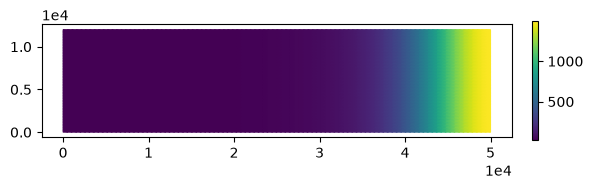

In [9]:
import icepack.plot

fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(u0, axes=axes)
fig.colorbar(colors, ax=axes, fraction=0.012, pad=0.04);

Below are some plots of basal shear stress and mass flux. The basal shear stress gets closer to zero near the terminus because of how we reduced the friction.

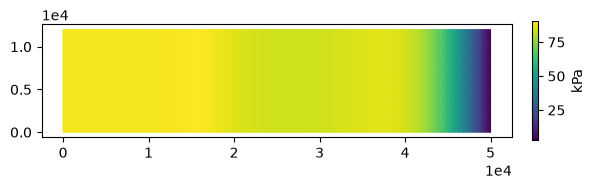

In [11]:
from firedrake import sqrt, inner

expr = -1e3 * C * ϕ * sqrt(inner(u0, u0)) ** (1 / m - 1) * u0
τ_b = firedrake.Function(V).interpolate(expr)
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(τ_b, axes=axes)
fig.colorbar(colors, label="kPa", fraction=0.012, pad=0.04);

There's a huge mass balance anomaly near the ice front, an artifact of our choice of initial conditions. As the simulation progresses, this initial transient should be propagated out of the domain.

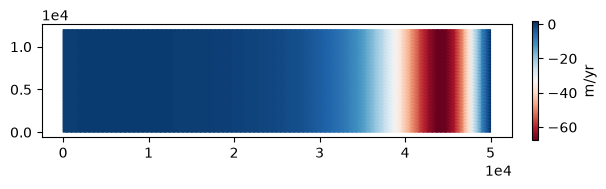

In [12]:
from firedrake import div

f = firedrake.Function(Q).interpolate(-div(h0 * u0))
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(f, cmap="RdBu", axes=axes)
fig.colorbar(colors, label="m/yr", fraction=0.012, pad=0.04);

## **Modelling**  
Now, we take our initial glacier state and project it forward until it reaches a steady state. We'll use a timestep of 6 months and run the simulation for 250 years. This is about enough time to propagate out the initial transients and arrive at a steady state of approximate mass and momentum balance. The accumulation rate is picked such that it roughly balances out the ice flux at the inflow boundary and is within the range of values observed in Greenland.

In [13]:
from tqdm.notebook import trange

# Set up timesteps, model time
num_years = 250
timesteps_per_year = 2
δt = 1.0 / timesteps_per_year
num_timesteps = num_years * timesteps_per_year

a_in = firedrake.Constant(1.7)
δa = firedrake.Constant(-2.7)
a = firedrake.Function(Q).interpolate(a_in + δa * x / Lx)

h = h0.copy(deepcopy=True)
u = u0.copy(deepcopy=True)

for step in trange(num_timesteps):
    h = solver_weertman.prognostic_solve(
        δt,
        thickness=h,
        velocity=u,
        accumulation=a,
        thickness_inflow=h0,
    )
    s = icepack.compute_surface(thickness=h, bed=b)

    u = solver_weertman.diagnostic_solve(
        velocity=u,
        thickness=h,
        surface=s,
        fluidity=A,
        friction=C,
    )

  0%|          | 0/500 [00:00<?, ?it/s]

Notice we have an extra step in the middle. Ice streams can be grounded or floating, so surface cannot just be calculated during the prognostic step like for ice shelves (which just depended on thickness + the density of ocean water and ice). After we calculate the ice thickness, we need to explicitly calculate a new surface elevation in a way that accounts for whether it is grounded or floating.

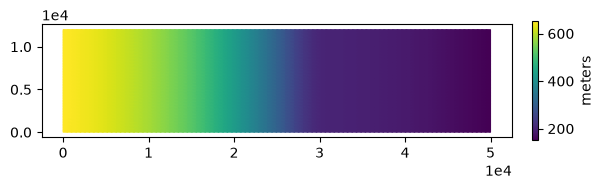

In [14]:
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(h, axes=axes)
fig.colorbar(colors, label="meters", fraction=0.012, pad=0.04);

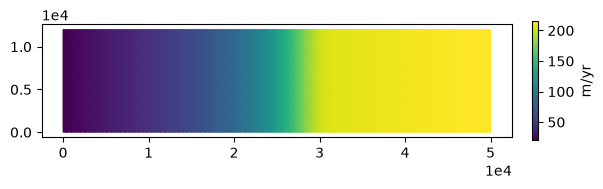

In [15]:
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(u, axes=axes)
fig.colorbar(colors, label="m/yr", fraction=0.012, pad=0.04);

We can see by plotting mass balance that the system is much closer to equilibrium than it was at the beginning.

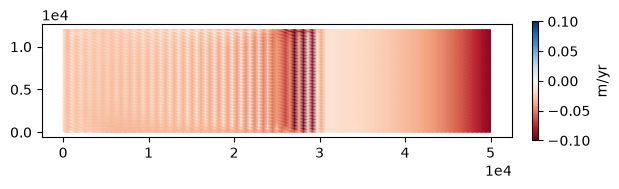

In [16]:
f = firedrake.Function(Q).interpolate(a - div(h * u))

fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(f, vmin=-0.1, vmax=+0.1, cmap="RdBu", axes=axes)
fig.colorbar(colors, label="m/yr", fraction=0.012, pad=0.04);

Finally, we can draw some transects through the domain to see what the surface, bed, and ice base elevation look like in the *x, z* plane.

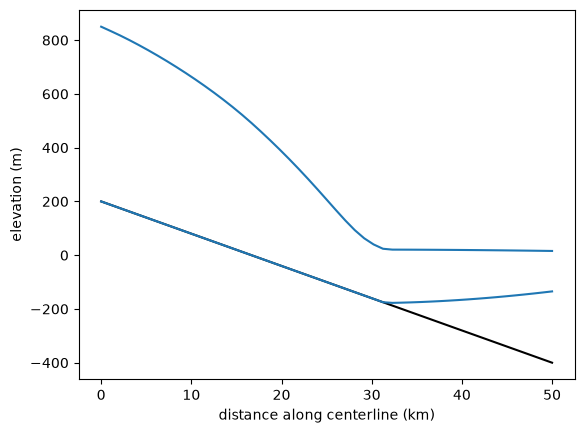

In [18]:
import numpy as np
import matplotlib.pyplot as plt

xs = np.array([(Lx * k / nx, 0) for k in range (nx + 1)])

ss = np.array(s.at(xs, tolerance=1e-10))
hs = np.array(h.at(xs, tolerance=1e-10))
bs = np.array(b.at(xs, tolerance=1e-10))

fig, axes = plt.subplots()
axes.plot(xs[:,0] / 1e3, bs, color="black")
axes.plot(xs[:,0] / 1e3, ss - hs, color="tab:blue")
axes.plot(xs[:,0] / 1e3, ss, color="tab:blue")
axes.set_xlabel("distance along centerline (km)")
axes.set_ylabel("elevation (m)");

The glacier exhibits the typical drop in thickness gradient as it crosses the grounding line.

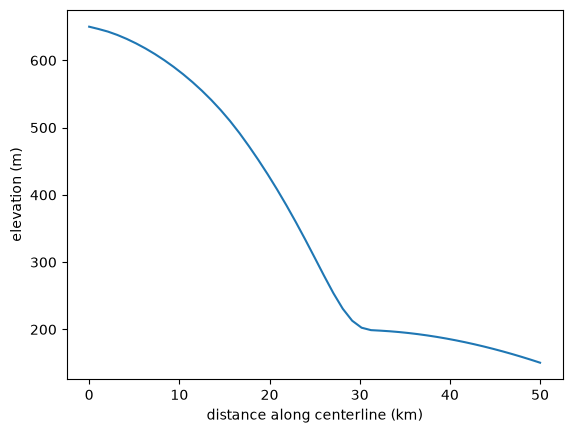

In [19]:
fig, axes = plt.subplots()
axes.plot(xs[:,0] / 1e3, hs)
axes.set_xlabel("distance along centerline (km)")
axes.set_ylabel("elevation (m)");

## **Recap**  
The demonstration above shows how to simulate the evolution of a grounded ice stream; while there are more fields to keep track of than for a floating ice shelf, the basic principles are still the same.  
  
Coming up with physically plausible synthetic test cases is difficult. The variables that we can control are the bed geometry, the accumulation rate, and the ice flux at inflow. To a certain extent, we can pick the friction coefficient, but this can change in ways that are difficult to predict as parts of the glacier begin to float. Our initial state was far out of mass balance and we let it evolve towards equilibrium, but we don't know ahead of time what surface slope or stretching rate the glacier will settle on in the end.  
  
The eventual steady state could be physically implausible for reasons that weren't obvious from the start. For example, if the ice strain rate increases beyond what we expect after a few years of model time, the mass flux at the inflow boundary could be much larger than what the influx and accumulation rate can supply, leading to an unphysically sharp drop in the surface. Preparing this demonstration required lots of trial and error to get the parameters just right, and that's to be expected.  
  
The bed elevation we used sloped down towards the ocean; had we instead used a bed elevation that sloped down going inland, the configuration would be unstable due to marine ice sheet instability. An interesting variation on this demo could be to use a bed geometry with several stable pinning points, interspersed with unstable retrograde slopes.

### **Using the Schoof sliding law**  
The Weertman sliding law shows that basal shear stress is proportional to some power of the ice sliding speed. In icepack, the stress is the functional derivative of firctional energy dissipation with respect to velocity. Here, we will use the Schoof sliding law to model glacier sliding differently.  

To modify the Weertman law for high ice speeds, the energy dissipation density is asymptotic and dependent on "small" or "large" velocities. A threshold velocity, *U0*, is not defined but 50 m/yr is used here. From here, we have a threshold stress, *τ0*.

In [20]:
U_0 = firedrake.Constant(50)
U = sqrt(inner(u, u))
τ_0 = firedrake.Function(Q).interpolate(C * (U_0**(1/m + 1) + U**(1/m + 1))**(1/(m + 1)))

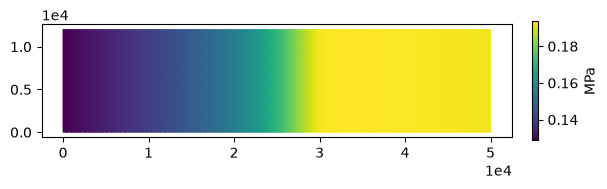

In [21]:
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(τ_0, axes=axes)
fig.colorbar(colors, label="MPa", fraction=0.012, pad=0.04);

The following function returns the kernel ofthe action functional associated to this sliding law, given the ice veloicty, elevation and yield stress. We only need to provide the inside of the integral - the model object applies the measures (*dx, ds*, etc) for you.

In [22]:
def schoof_friction(**kwargs):
    u = kwargs["velocity"]
    h = kwargs["thickness"]
    s = kwargs["surface"]
    τ_0 = kwargs["yield_stress"]

    ϕ = 1 - ρ_W / ρ_I * firedrake.max_value(0, h - s) / h
    U = sqrt(inner(u, u))
    return τ_0 * ϕ * (
        (U_0**(1 / m + 1) + U**(1 / m + 1))**(m / (m + 1)) - U_0
    )    

To calculate basal shear, we take advantage of the symbolic differentiation features of the form language by creating free energy dissipation (*F*) and then calling *firedrake.diff* on it.

In [23]:
F = schoof_friction(
    velocity=u,
    thickness=h,
    surface=s,
    yield_stress=τ_0,
)
τ = firedrake.Function(V).interpolate(-firedrake.diff(F, u))

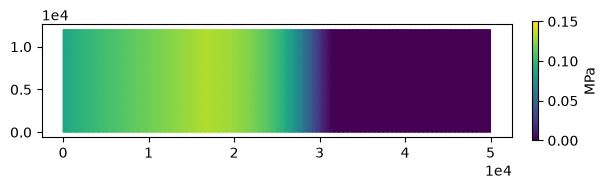

In [24]:
fig, axes= icepack.plot.subplots()
colors = firedrake.tripcolor(τ, vmin=0, vmax=0.15, axes=axes)
fig.colorbar(colors, label="MPa", fraction=0.012, pad=0.04);

This matches up with what we expect: higher stress at the grounded part of the ice stream and decreasing to 0 toward the grounding line.  

Now we can create a new *IceStream* object that will use this function to calculate the action rather than the Weertman sliding law:

In [25]:
model_schoof = icepack.models.IceStream(friction=schoof_friction)

Now, we do a diagnostic solve with this new model and see how different it is from the velocity obtained with the Weertman sliding law.

In [27]:
solver_schoof = icepack.solvers.FlowSolver(model_schoof, **opts)
u_schoof = solver_schoof.diagnostic_solve(
    velocity=u,
    thickness=h,
    surface=s,
    fluidity=A,
    yield_stress=τ_0,
)

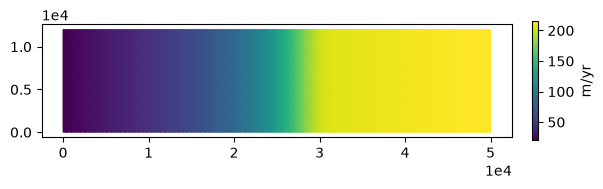

In [28]:
fig, axes = icepack.plot.subplots()
colors = firedrake.tripcolor(u_schoof, axes=axes)
fig.colorbar(colors, label="m/yr", fraction=0.012, pad=0.04);

In [29]:
icepack.norm(u - u_schoof)

np.float64(4.286650523571107)

As expected, the resulting velocities are practically the same.

### **Response to perturbations**  
The steady state we've found is roughly an equilibrium for both the Weertman and Schoof sliding laws. Now, we'll increase the melt rate under the floating portion and see how the system responds. We'll add an extra 1 m/yr of melting in the right-hand side of the domain. To mak eit more realistic, we might set the melt rate to be dependent on depth below sea level, or use a plume model.

In [30]:
from firedrake import conditional

# adjust melt rate
expr = a_in + δa * x / Lx - conditional(x / Lx > 0.5, 1.0, 0.0)
a = firedrake.Function(Q).interpolate(expr)

In [31]:
num_years = 100
timesteps_per_year = 2
δt = 1.0 / timesteps_per_year
num_timesteps = num_years * timesteps_per_year

# Wrap the same loop as above with a function that takes either model as an argument
def run_simulation(solver, h, s, u, **kwargs):
    for step in trange(num_timesteps):
        h = solver.prognostic_solve(
            δt,
            thickness=h,
            velocity=u,
            accumulation=a,
            thickness_inflow=h0,
        )
        s = icepack.compute_surface(thickness=h, bed=b)
        
        u = solver.diagnostic_solve(
            velocity=u,
            thickness=h,
            surface=s,
            **kwargs,
        )

    return h, s, u

# Pass in Weertman model
h_weertman, s_weertman, u_weertman = run_simulation(
    solver_weertman, h, s, u, fluidity=A, friction=C
)
# Pass in Schoof model
h_schoof, s_schoof, u_schoof = run_simulation(
    solver_schoof, h, s, u_schoof, fluidity=A, yield_stress=τ_0
)

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

Now we plot the difference in thickness between the Weertman and Schoof laws. The glacier loses more mass over the grounded region and less under the ice shelf with the Schoof law. When the sliding relation becomes more plastic, the bed can take up less of the increased driving stress resulting from steeper surface slopes, so that changes under the ice shelf are evident further upstream.

/home/rileetho/ENTER/envs/firedrake/lib/python3.12/site-packages/firedrake/function.py:560: FutureWarning: The ``Function.at`` method is deprecated and will be removed in a future release. Please use the ``PointEvaluator`` class instead.
  warnings.warn(


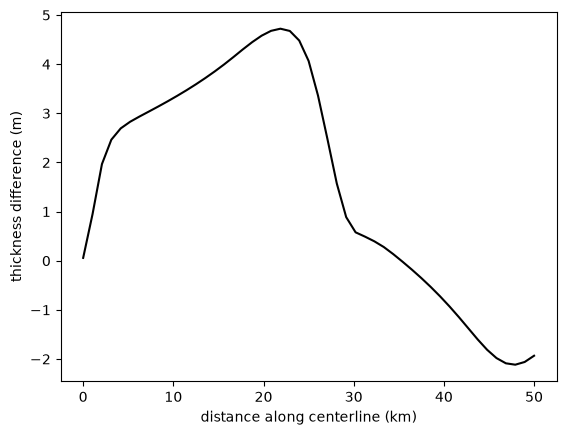

In [32]:
hs_weertman = np.array(h_weertman.at(xs, tolerance=1e-10))
hs_schoof = np.array(h_schoof.at(xs, tolerance=1e-10))

fig, axes = plt.subplots()
axes.plot(xs[:, 0] / 1e3, hs_weertman - hs_schoof, color="black")
axes.set_xlabel("distance along centerline (km)")
axes.set_ylabel("thickness difference (m)");

To conclude, the Schoof sliding law is arguably more physically realistic than the Weertman sliding law for fast-flowing glaciers and ice streams. While icepack defaults to Weertman, it is easy to replace with Schoof:  
1) Write a function that calculates energy dissipation from Schoof-type sliding
2) Pass the function to the constructor of *IceStream* model object we use to calculate velocity
3) Pass in all input fields to the *diagnostic_solve* method - we don't have to rewrite any methods of *IceStream*, despite the fact that there are more input fields to the Schoof law than to Weertman. 